# FSAI Stereo Depth — Results Notebook

**Run:** 2026-10-28 · **GPU:** RTX 3070 Laptop 8 GB · **Driver:** 621.01
**SDK:** ZED SDK 5.5.1 / pyzed 5.5.1 · **Mode:** PERFORMANCE (H.264 3000 kbps)

This notebook collects the final stereo, DepthNet, SGBM and ZED SDK results. It
reads the JSON/PNG outputs only; it does not rerun inference or need a GPU.

The two main reports are:

- `STEREO_DEPTH_VALIDATION.md`
- `ZED_SDK_SIMULATION_RESULT.md`


In [1]:
from pathlib import Path
import json
from IPython.display import Markdown, Image, display

ROOT = Path.cwd()
stereo = json.loads((ROOT / 'outputs/stereo_validation/results.json').read_text())
sdk = json.loads((ROOT / 'outputs/sdk_three_way/results.json').read_text())
env = json.loads((ROOT / 'outputs/environment.json').read_text())

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join('---' for _ in headers) + ' |']
    lines += ['| ' + ' | '.join(str(c) for c in r) + ' |' for r in rows]
    return '\n'.join(lines)

def f(v, n=3):
    return '—' if v is None else f'{v:.{n}f}'

print('stereo run:', stereo['run_utc'])
print('stereo device:', stereo['inference'].get('device'), '| torch', env['torch'])
print('SDK capture:', sdk['capture']['sdk_version'], sdk['capture']['sdk_depth_mode'])


stereo run: 2026-10-28T21:32:33.434724+00:00
stereo device: 0 | torch 2.11.0+cu128
SDK capture: 5.5.1 PERFORMANCE


## 1. Stereo geometry and SGBM (clean prepared pair)

In [2]:
main = stereo['main']; pw = main['pairwise']; cm = main['common_pixel_metrics']
rows = []
for name in pw:
    p, c = pw[name], cm[name]
    rows.append([name, f"{p['pixels']:,}", f"{p['coverage_of_gt']*100:.2f}%",
                 f(p['mae_m']), f(p['rmse_m']), f(p['bias_m'], 3),
                 f(c['mae_m']), f(c['median_abs_error_m']), f(c['p90_abs_error_m'])])
display(Markdown('### Main metrics\n' + table(
    ['Method', 'Valid px', 'Coverage', 'MAE', 'RMSE', 'Bias', 'MAE common',
     'Median common', 'P90 common'], rows)))
d = stereo['disparity']
display(Markdown(f"""
**Geometry:** f = {stereo['geometry']['K'][0][0]:.3f} px,
B = {stereo['geometry']['baseline_m']*1000:.4f} mm;
epipolar median |dy| {stereo['epipolar']['median_abs_dy_px']:.3f} px;
SGBM median |Δd| {d['median_abs_disparity_px']:.3f} px,
{d['within_1px_pct']*100:.1f}% within 1 px.
"""))


### Main metrics
| Method | Valid px | Coverage | MAE | RMSE | Bias | MAE common | Median common | P90 common |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| DepthNet | 270,876 | 100.00% | 2.436 | 2.664 | 1.809 | 2.530 | 2.484 | 2.998 |
| SGBM | 197,731 | 73.00% | 0.791 | 4.301 | 0.453 | 0.791 | 0.013 | 0.549 |


**Geometry:** f = 636.250 px,
B = 119.7245 mm;
epipolar median |dy| 0.117 px;
SGBM median |Δd| 0.265 px,
89.5% within 1 px.


## 2. ZED SDK three-way result (PERFORMANCE mode)

The SDK capture is **PERFORMANCE**, not NEURAL, and the stream is H.264
3000 kbps. DepthNet was evaluated on the R/B-corrected SDK left image
(`sdk_left_corrected.png`); the raw `sdk_left.png` had a channel swap that
inflated DepthNet to 9.34 m and is not used for the fair comparison.


In [3]:
s = sdk['sdk']; d = sdk['depthnet_same_image']; sc = sdk['sdk_common']; dc = sdk['depthnet_common']
rows = [
    ['ZED SDK', f"{s['pixels']:,}", f"{s['coverage']*100:.2f}%", f(s['mae_m']), f(s['rmse_m']),
     f(s['bias_m'], 3), f(s['median_abs_error_m']), f(s['p90_abs_error_m']), f"{s['bad_3m']*100:.1f}%"],
    ['DepthNet', f"{d['pixels']:,}", f"{d['coverage']*100:.2f}%", f(d['mae_m']), f(d['rmse_m']),
     f(d['bias_m'], 3), f(d['median_abs_error_m']), f(d['p90_abs_error_m']), f"{d['bad_3m']*100:.1f}%"],
]
display(Markdown('### SDK vs DepthNet on the same image\n' + table(
    ['Method', 'Valid px', 'Coverage', 'MAE', 'RMSE', 'Bias', 'Median', 'P90', '≥3 m'], rows)))
display(Markdown(f"""
On the {sdk['common_pixels']:,} common pixels: SDK MAE **{sc['mae_m']:.3f} m**,
DepthNet MAE **{dc['mae_m']:.3f} m**. The SDK has the lower median
({sc['median_abs_error_m']:.3f} vs {dc['median_abs_error_m']:.3f} m) but the
heavier tail (RMSE {sc['rmse_m']:.3f} vs {dc['rmse_m']:.3f} m). This is a mixed
result, not a single-method win.
"""))


### SDK vs DepthNet on the same image
| Method | Valid px | Coverage | MAE | RMSE | Bias | Median | P90 | ≥3 m |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ZED SDK | 251,213 | 92.74% | 2.800 | 6.879 | 2.725 | 1.631 | 2.910 | 9.7% |
| DepthNet | 270,876 | 100.00% | 2.211 | 2.464 | 1.567 | 2.122 | 2.725 | 7.1% |


On the 251,213 common pixels: SDK MAE **2.800 m**,
DepthNet MAE **2.210 m**. The SDK has the lower median
(1.631 vs 2.142 m) but the
heavier tail (RMSE 6.879 vs 2.428 m). This is a mixed
result, not a single-method win.


## 3. Per-depth-bin SDK table

In [4]:
rows = []
for b in sdk['bins']:
    for name in ('ZED SDK', 'DepthNet'):
        x = b[name]
        rows.append([name, f"{b['lo']}–{b['hi']}", f"{b['common']:,}",
                     f"{x['coverage']*100:.1f}%", f(x['mae_m']), f(x['rmse_m']),
                     f(x['bias_m'], 3), f(x['p90_abs_error_m'])])
display(Markdown(table(['Method', 'Truth bin (m)', 'Common px', 'Coverage',
                        'MAE', 'RMSE', 'Bias', 'P90'], rows)))


| Method | Truth bin (m) | Common px | Coverage | MAE | RMSE | Bias | P90 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ZED SDK | 0–2 | 107,284 | 95.9% | 2.387 | 4.218 | 2.387 | 2.458 |
| DepthNet | 0–2 | 107,284 | 100.0% | 2.337 | 2.355 | 2.337 | 2.658 |
| ZED SDK | 2–4 | 86,036 | 96.8% | 1.701 | 4.565 | 1.700 | 1.824 |
| DepthNet | 2–4 | 86,036 | 100.0% | 2.070 | 2.116 | 2.070 | 2.517 |
| ZED SDK | 4–6 | 28,583 | 98.2% | 2.096 | 5.967 | 1.922 | 2.553 |
| DepthNet | 4–6 | 28,583 | 100.0% | 1.831 | 2.010 | 1.815 | 3.184 |
| ZED SDK | 6–8 | 12,226 | 83.1% | 10.313 | 18.893 | 10.049 | 34.879 |
| DepthNet | 6–8 | 12,226 | 100.0% | 0.931 | 1.195 | 0.741 | 2.156 |
| ZED SDK | 8–10 | 5,673 | 66.4% | 7.053 | 12.516 | 6.847 | 17.421 |
| DepthNet | 8–10 | 5,673 | 100.0% | 0.954 | 1.134 | -0.842 | 1.785 |
| ZED SDK | 10–12 | 4,193 | 70.0% | 6.110 | 11.013 | 5.706 | 17.195 |
| DepthNet | 10–12 | 4,193 | 100.0% | 2.655 | 2.772 | -2.655 | 3.736 |
| ZED SDK | 12–14 | 2,398 | 64.8% | 6.989 | 13.345 | 6.389 | 23.824 |
| DepthNet | 12–14 | 2,398 | 100.0% | 4.198 | 4.287 | -4.198 | 5.276 |
| ZED SDK | 14–16 | 2,065 | 60.0% | 9.057 | 17.914 | 8.212 | 41.455 |
| DepthNet | 14–16 | 2,065 | 100.0% | 5.915 | 5.985 | -5.915 | 7.137 |
| ZED SDK | 16–18 | 1,702 | 60.5% | 5.364 | 11.746 | 4.068 | 6.902 |
| DepthNet | 16–18 | 1,702 | 100.0% | 7.898 | 7.944 | -7.898 | 9.125 |
| ZED SDK | 18–20 | 1,053 | 58.1% | 4.454 | 8.876 | 2.391 | 6.154 |
| DepthNet | 18–20 | 1,053 | 100.0% | 9.842 | 9.873 | -9.842 | 10.906 |

## 4. Figures

**fig01_depth_panels.png**

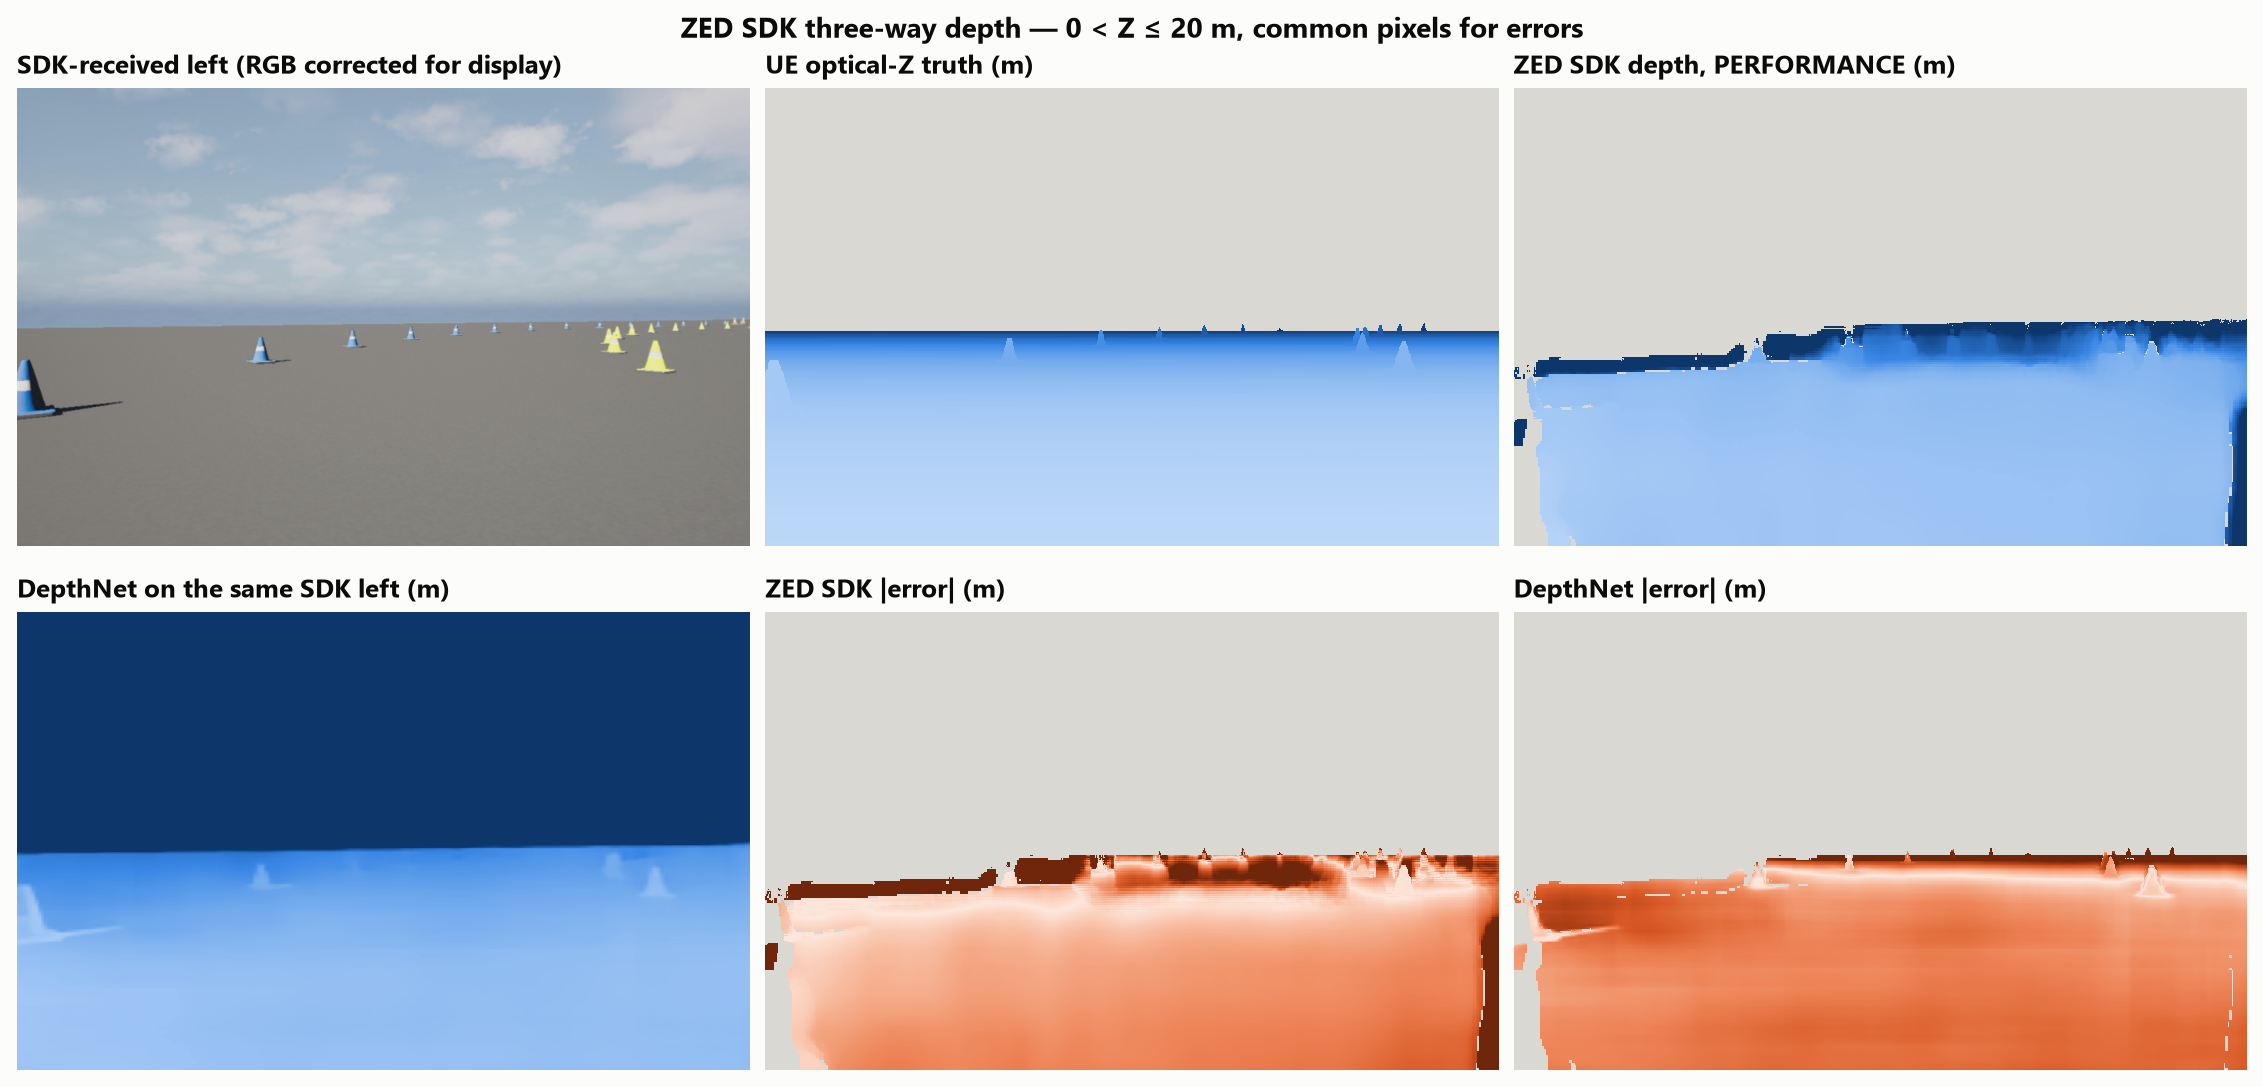

**fig02_scatter.png**

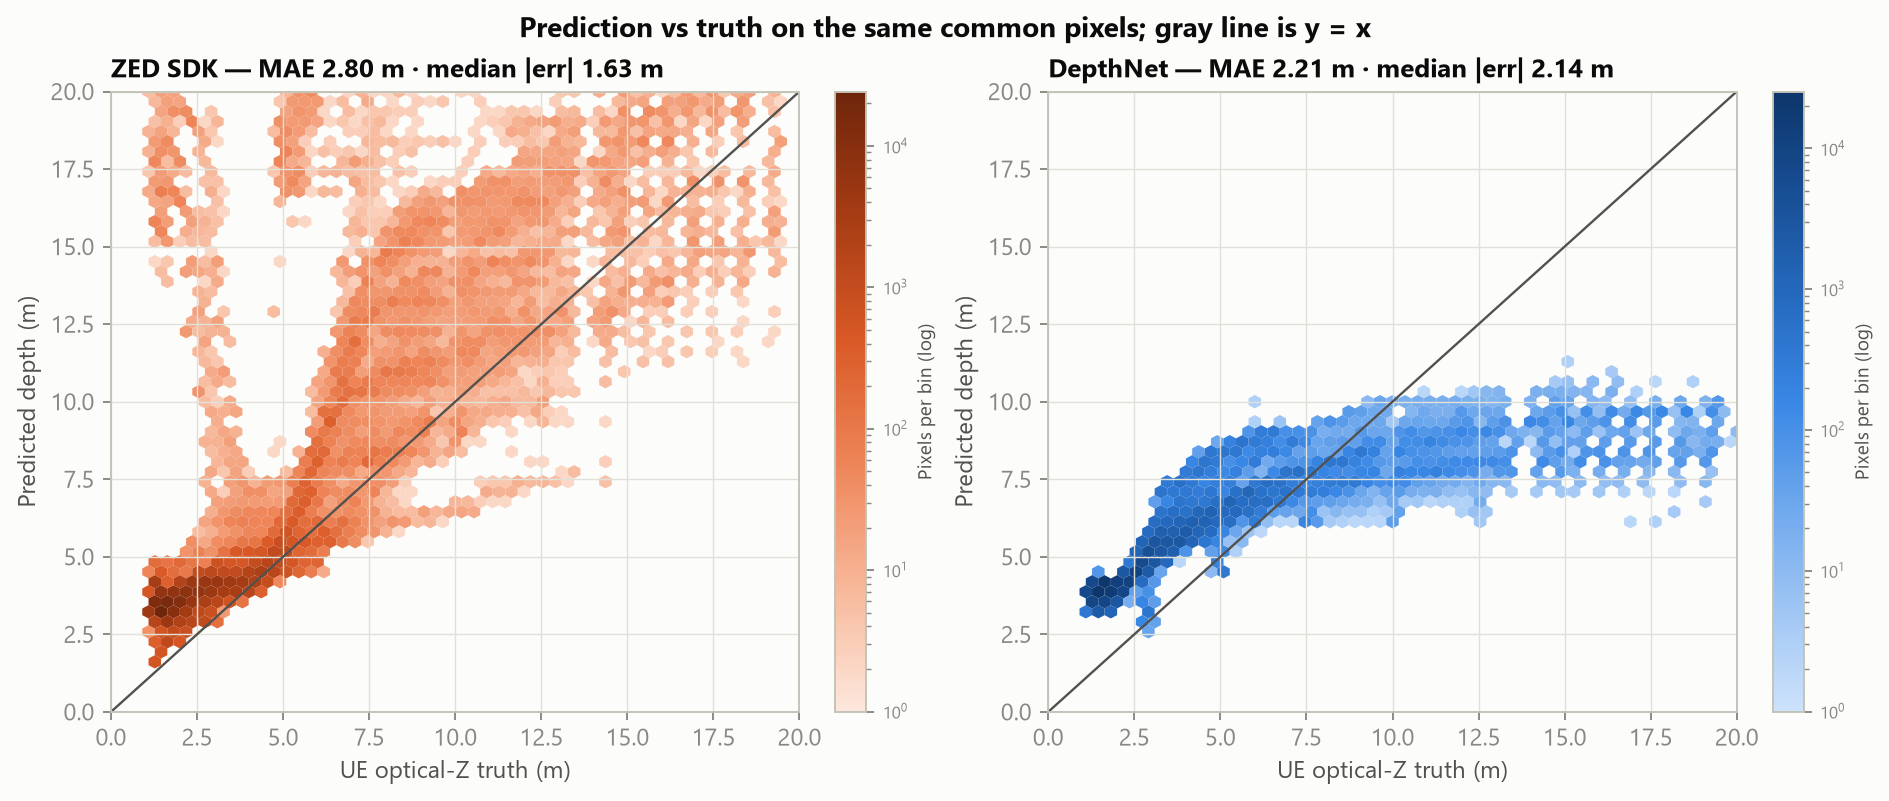

**fig03_bins.png**

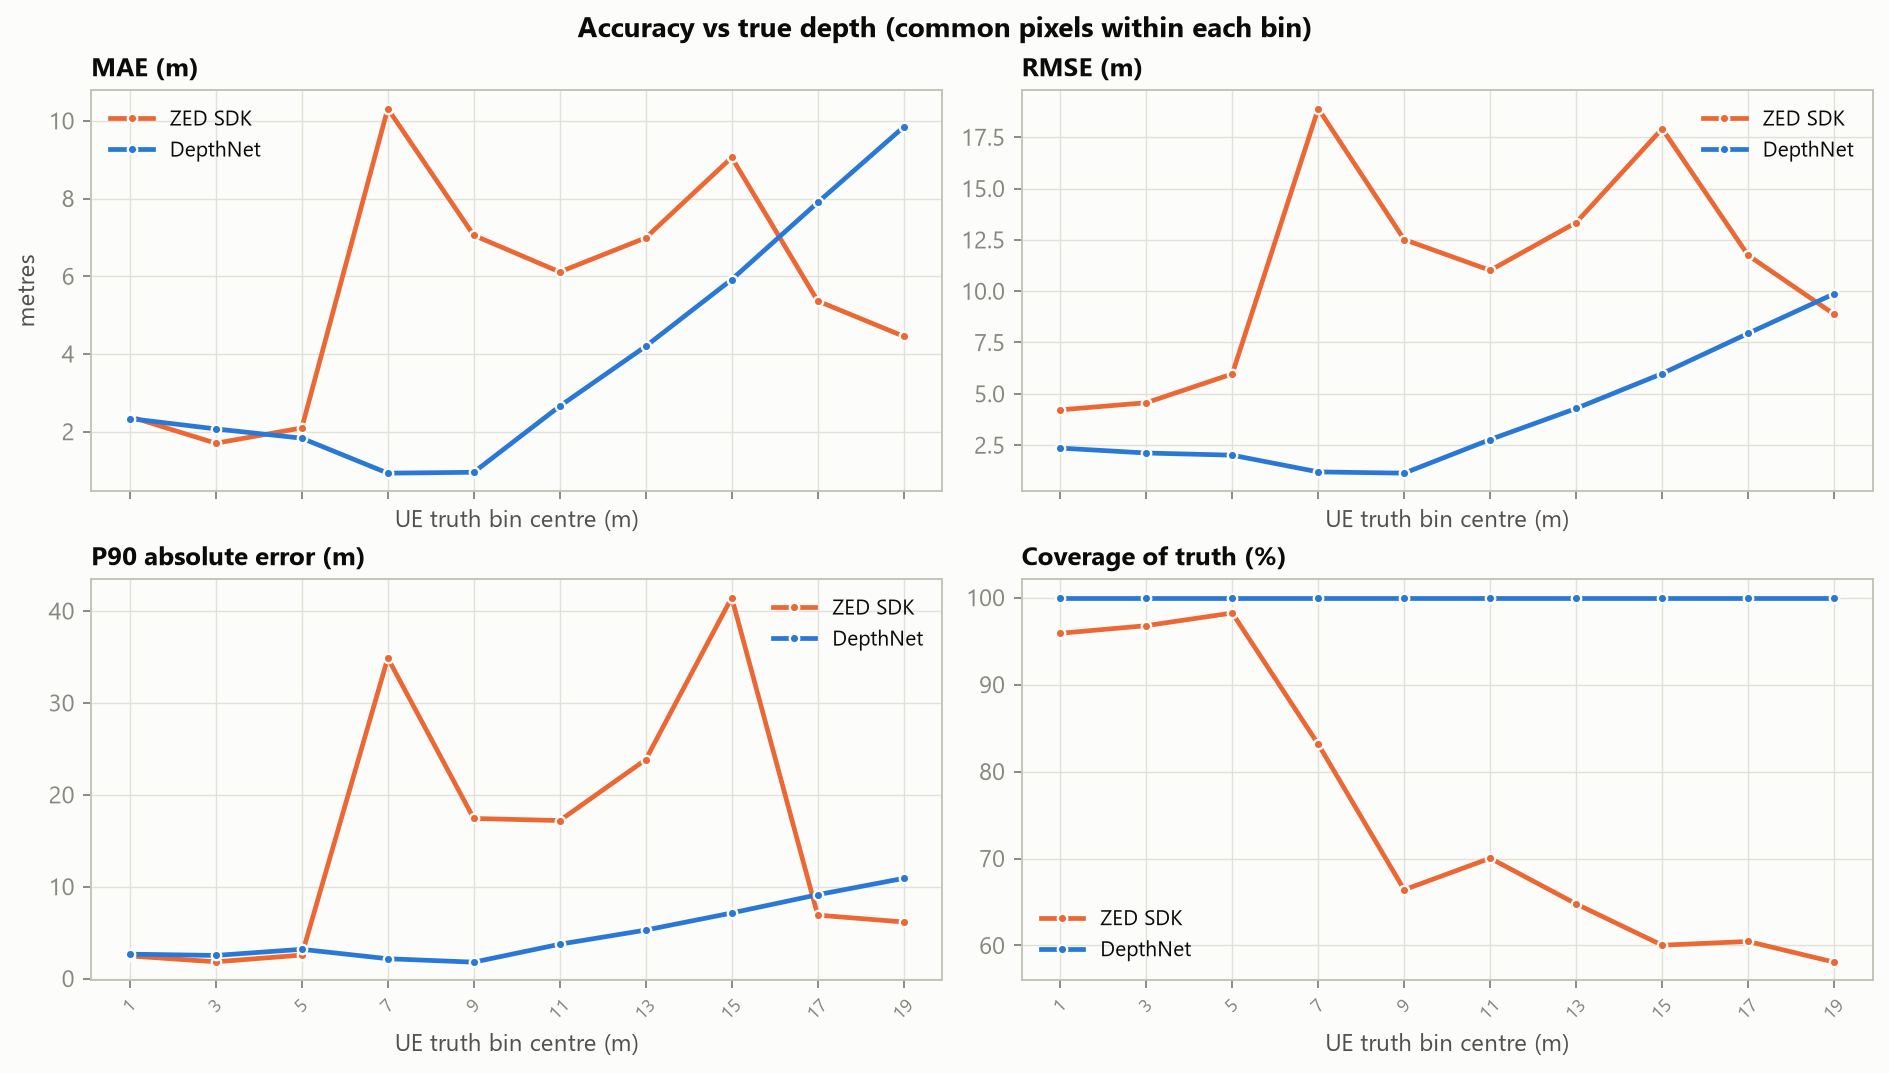

**fig04_thresholds.png**

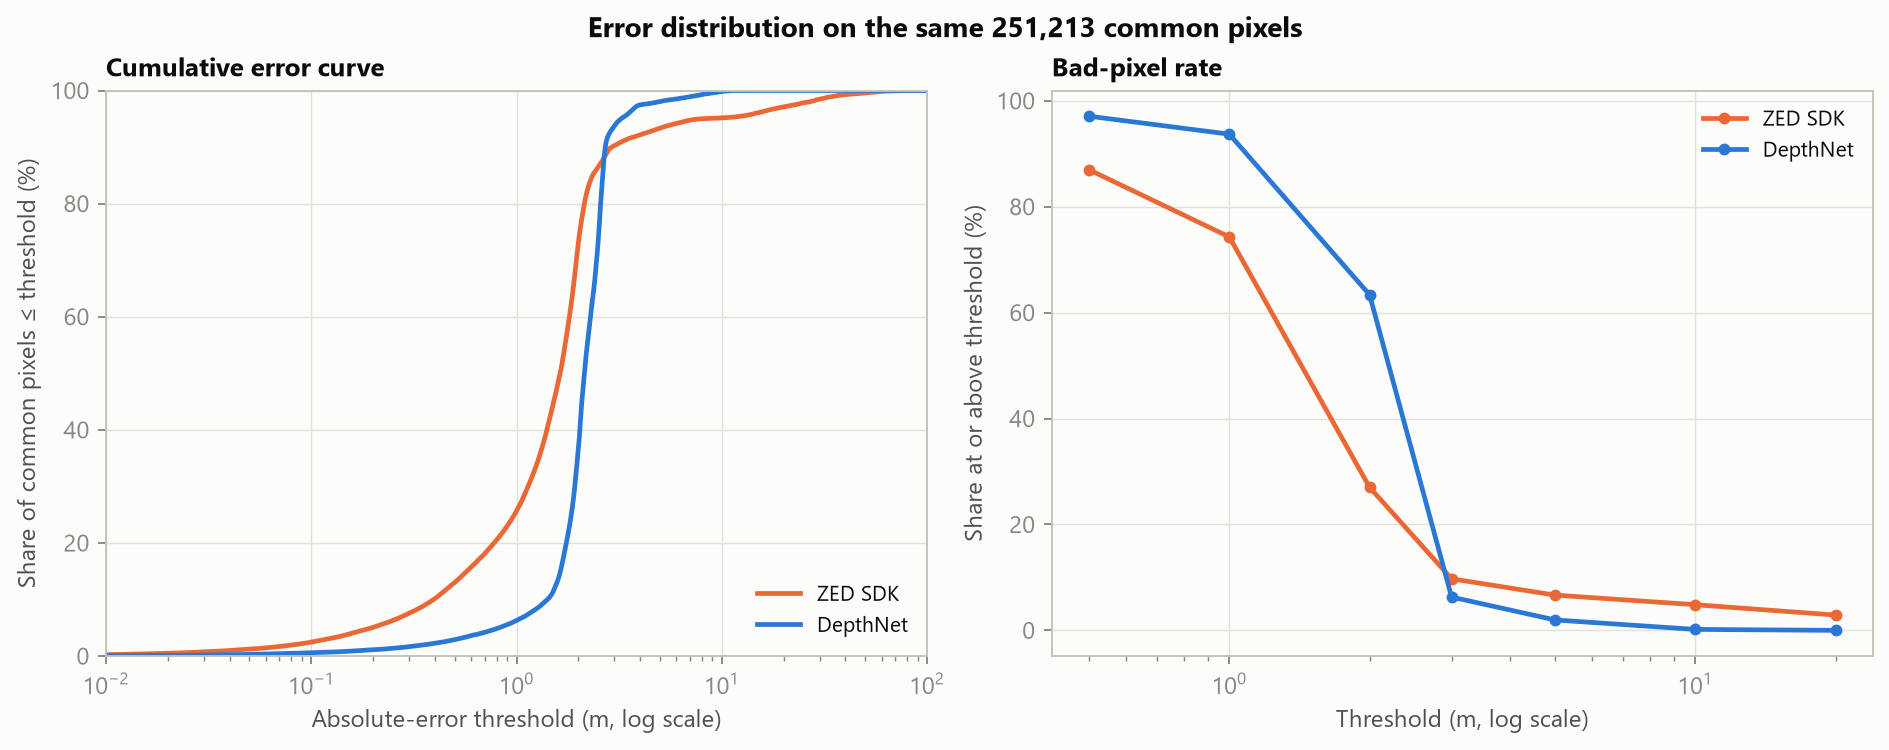

**fig05_headline.png**

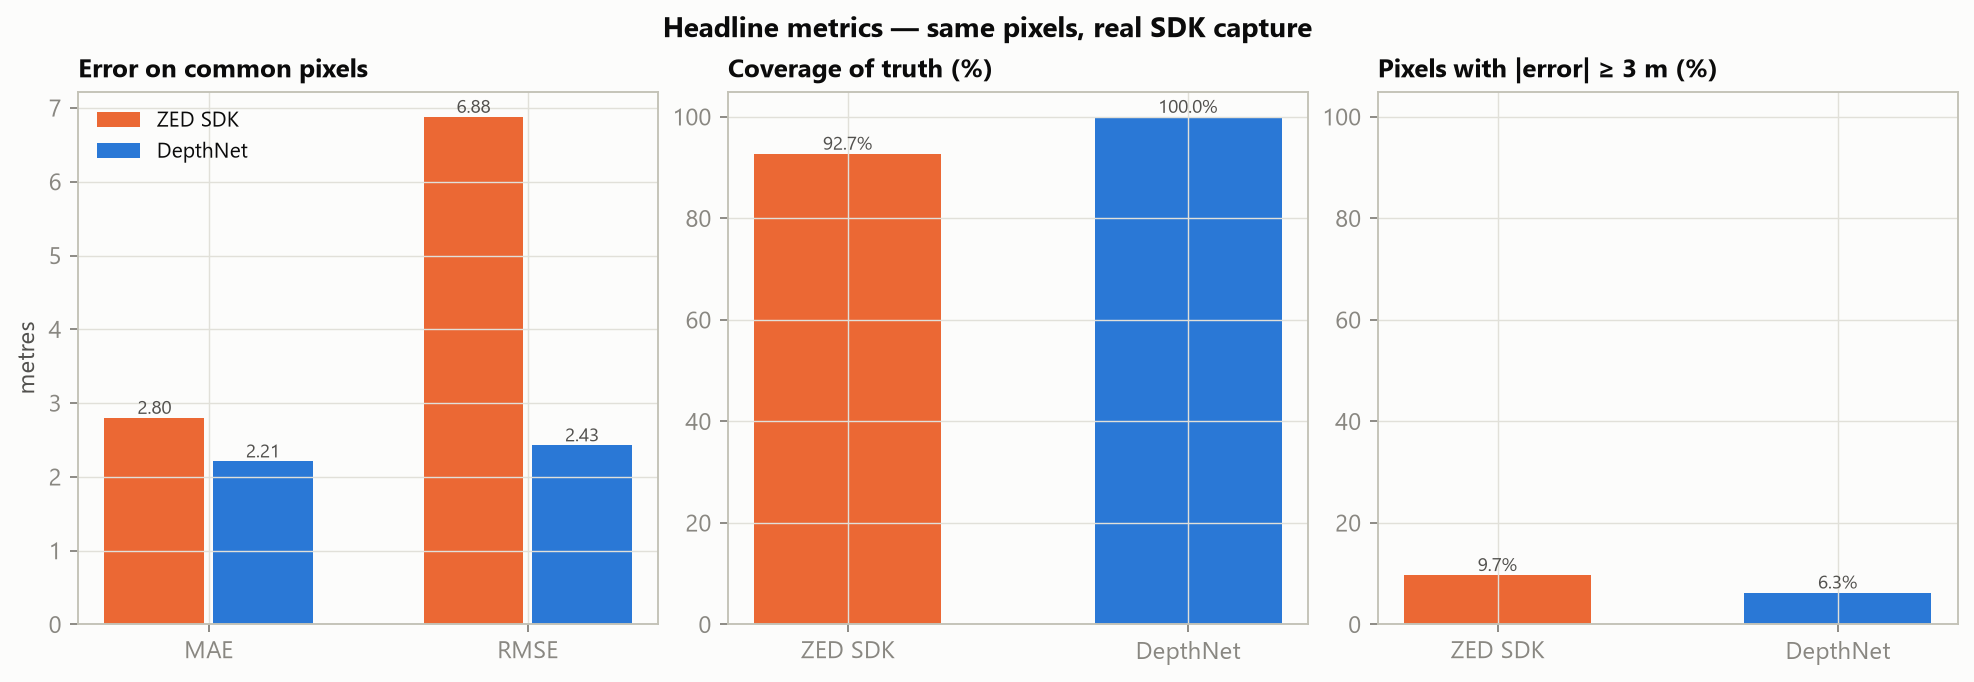

**fig06_process.png**

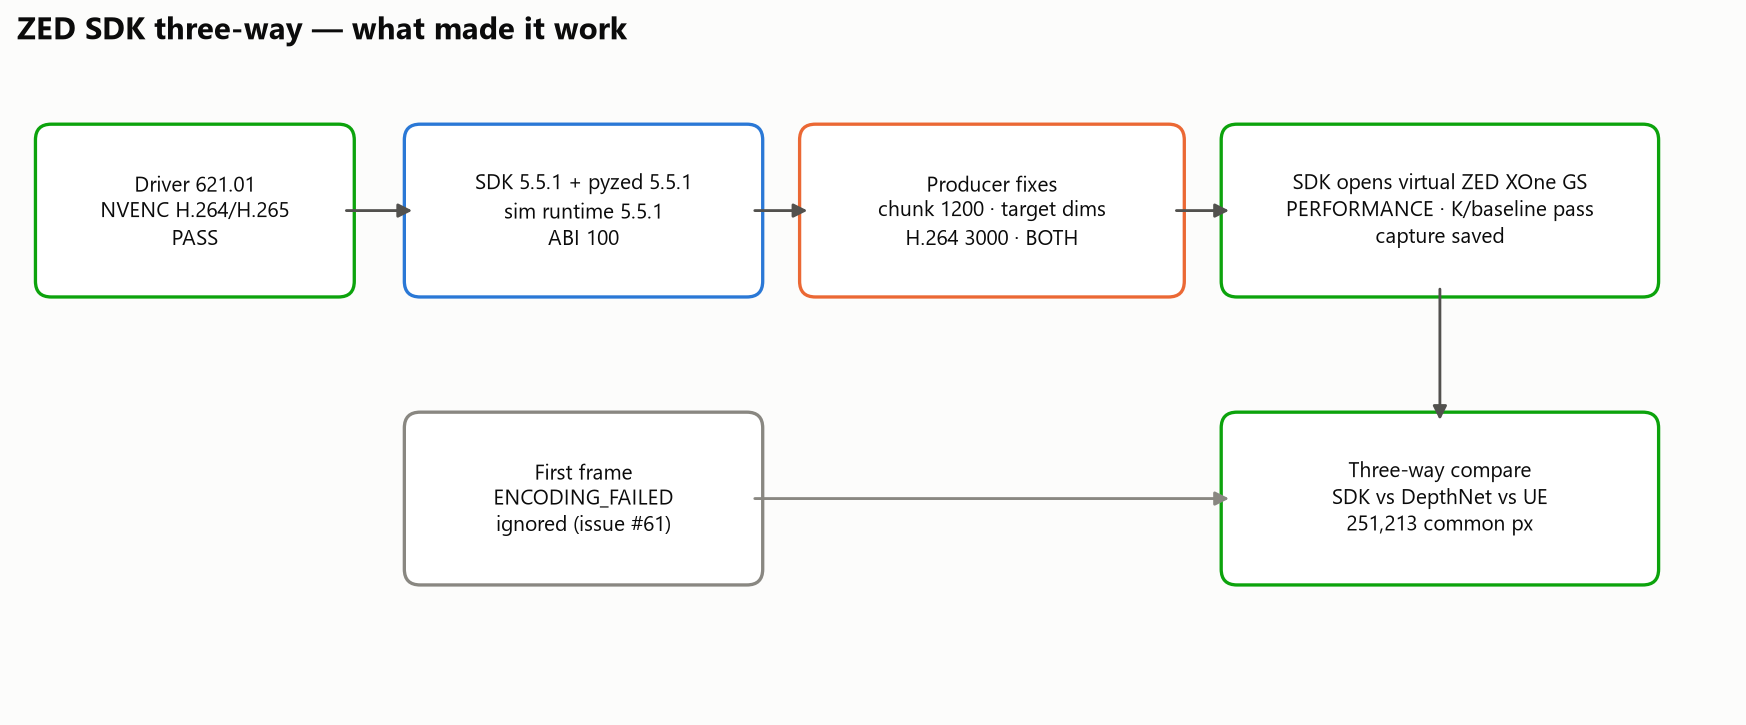

In [5]:
for name in ['fig01_depth_panels.png', 'fig02_scatter.png', 'fig03_bins.png',
             'fig04_thresholds.png', 'fig05_headline.png', 'fig06_process.png']:
    p = ROOT / 'outputs/sdk_three_way/figures' / name
    if p.is_file():
        display(Markdown(f'**{name}**'))
        display(Image(filename=str(p), width=1000))


**fig02_depth_comparison.png**

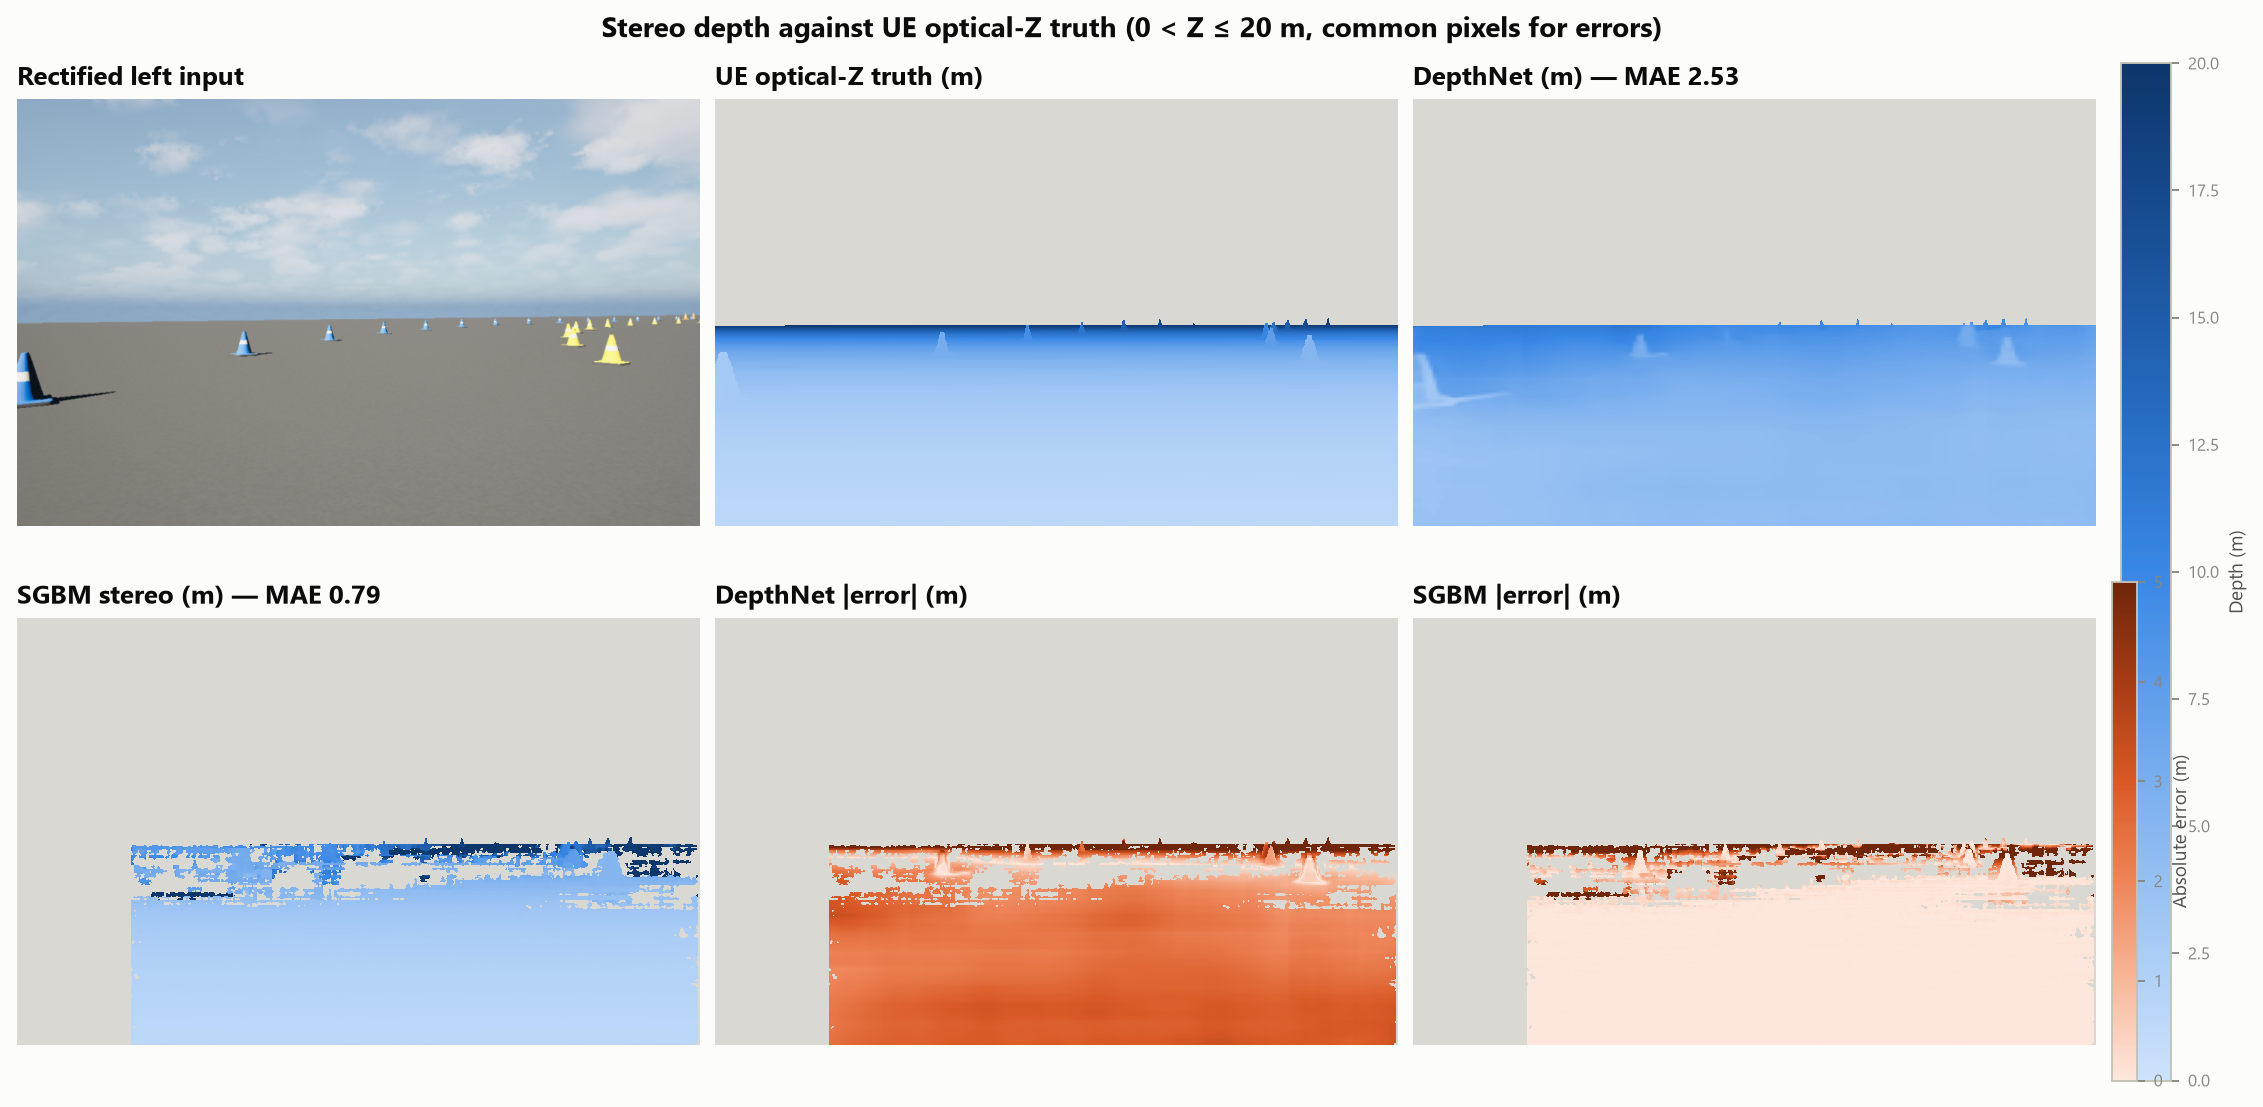

**fig04_error_vs_depth.png**

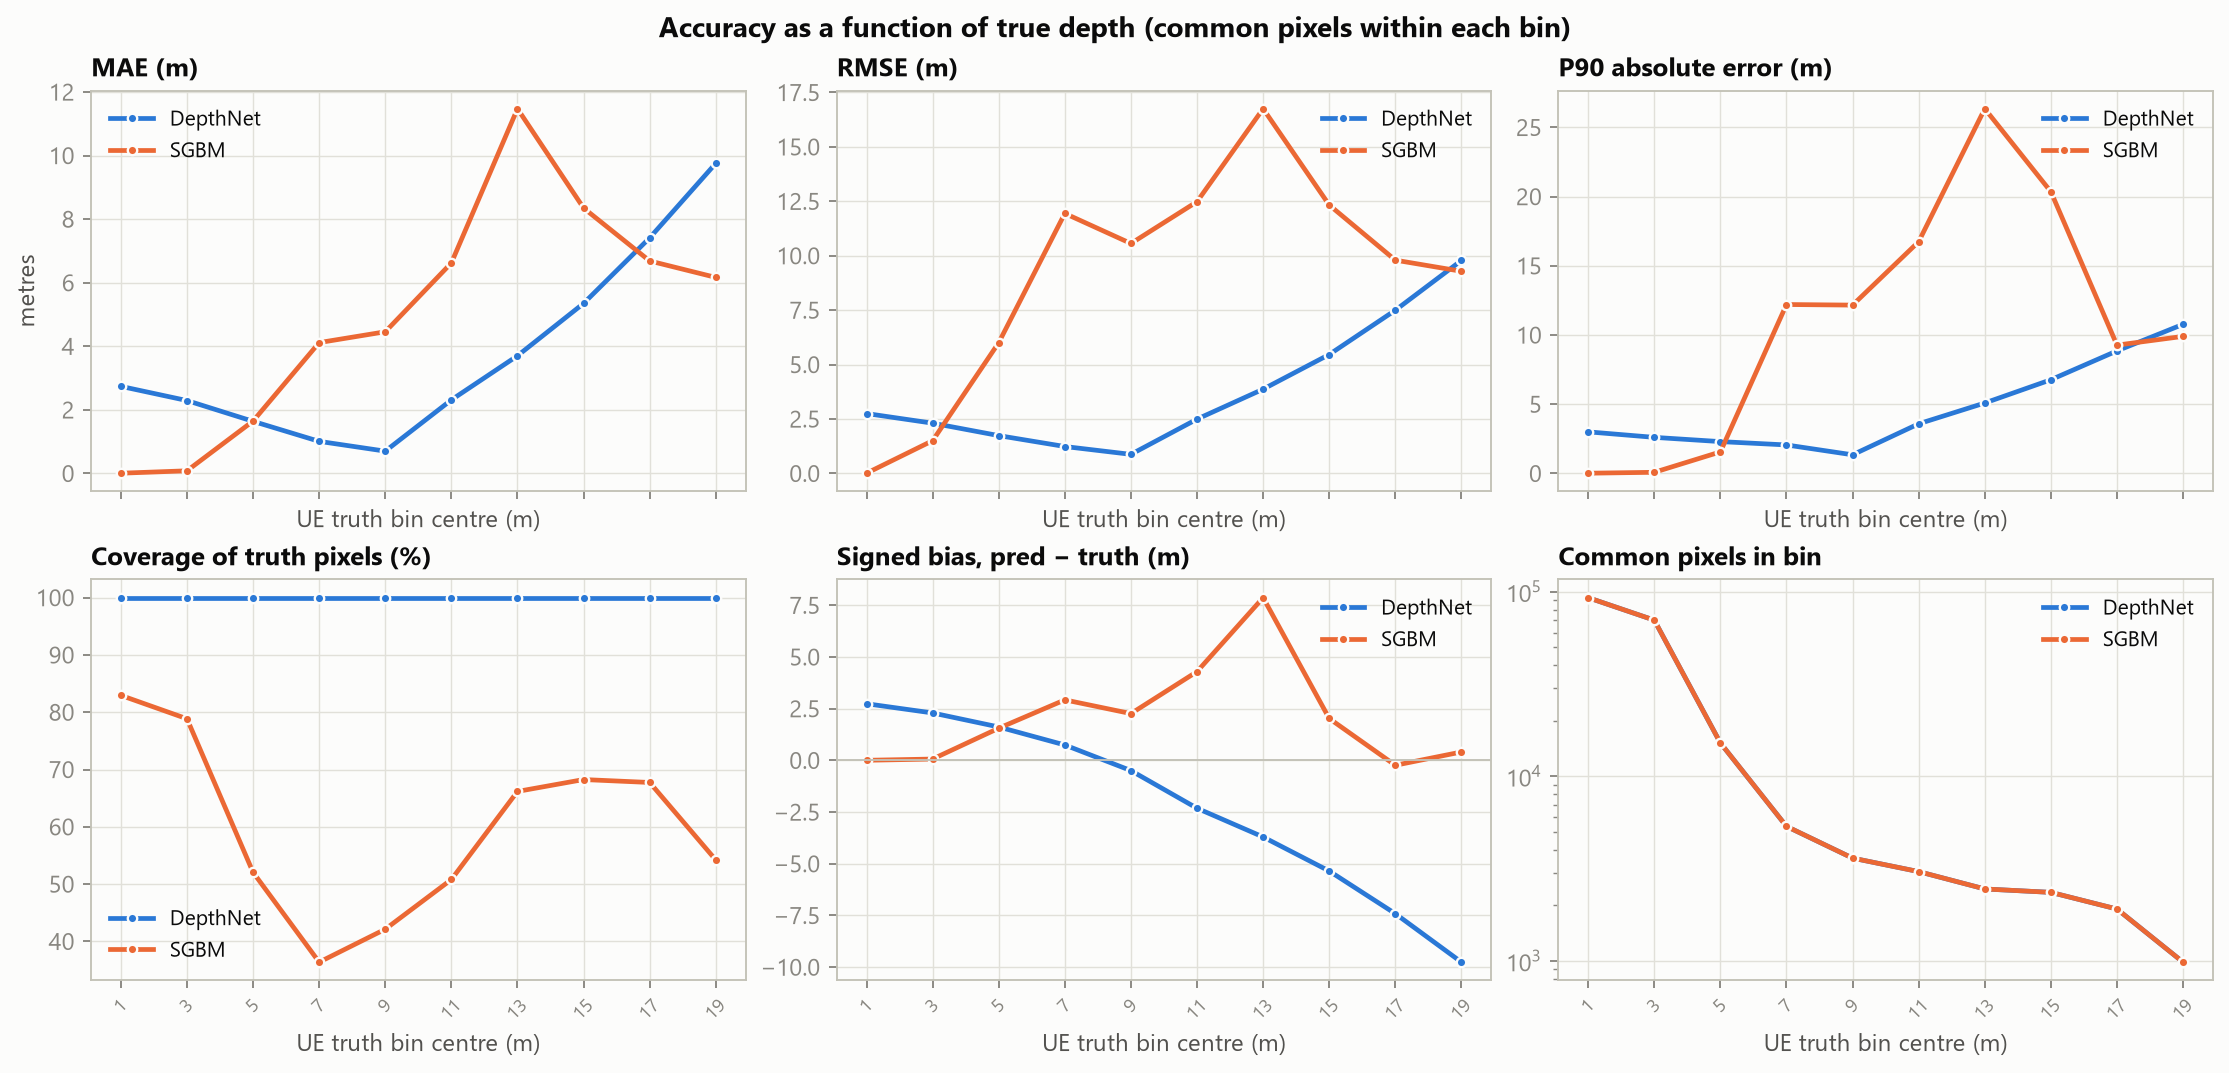

**fig08_disparity_consistency.png**

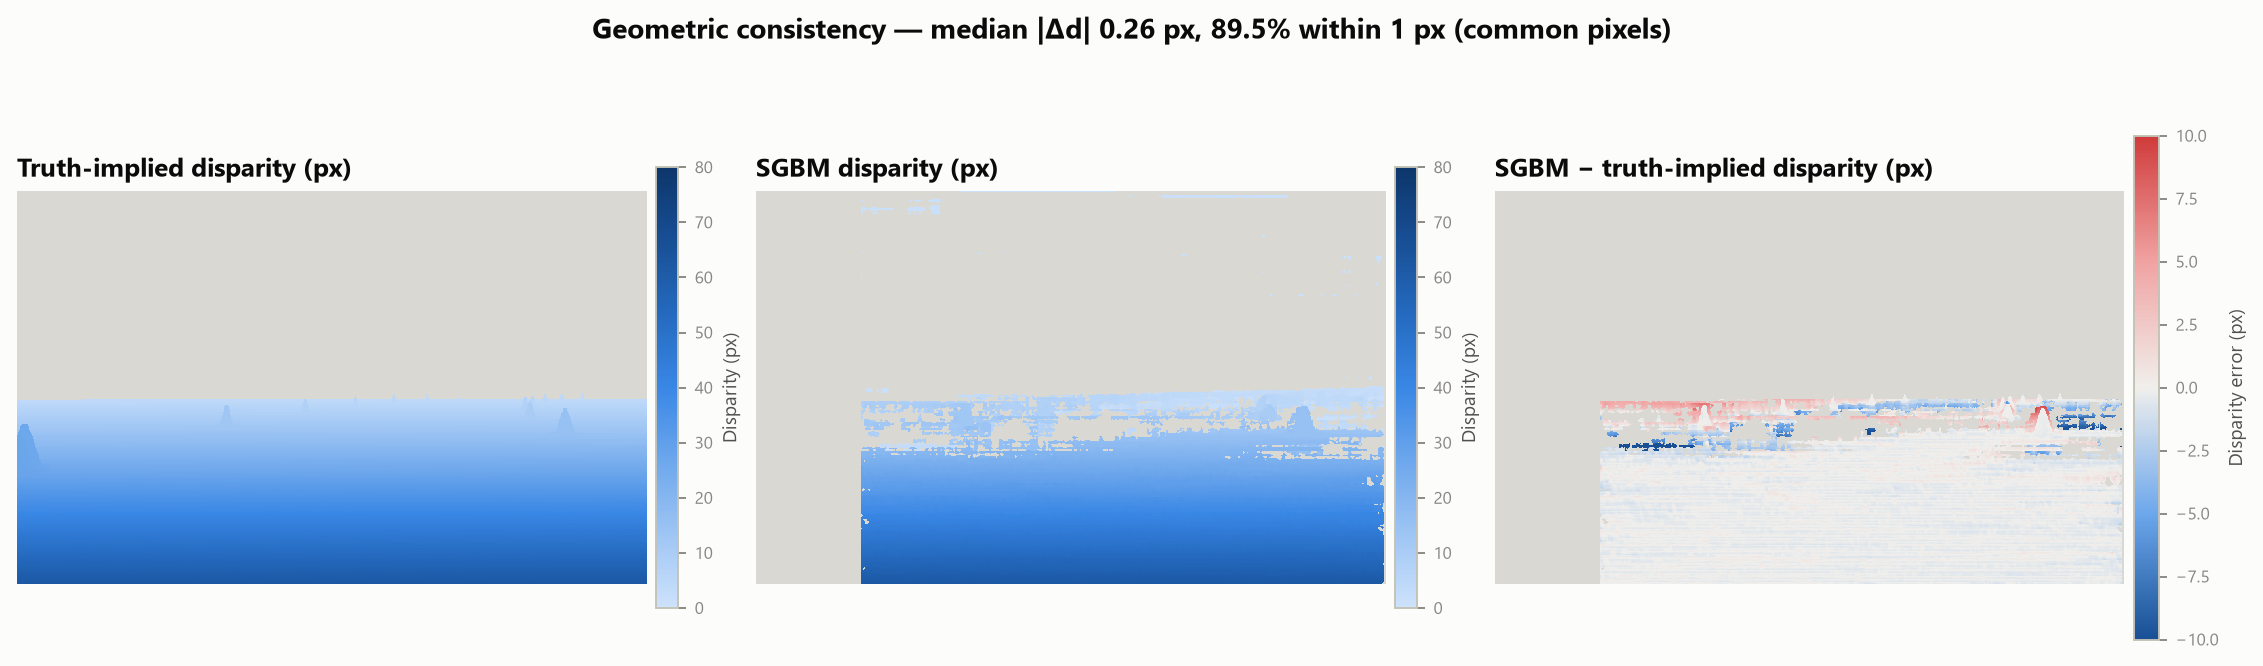

**fig09_epipolar_check.png**

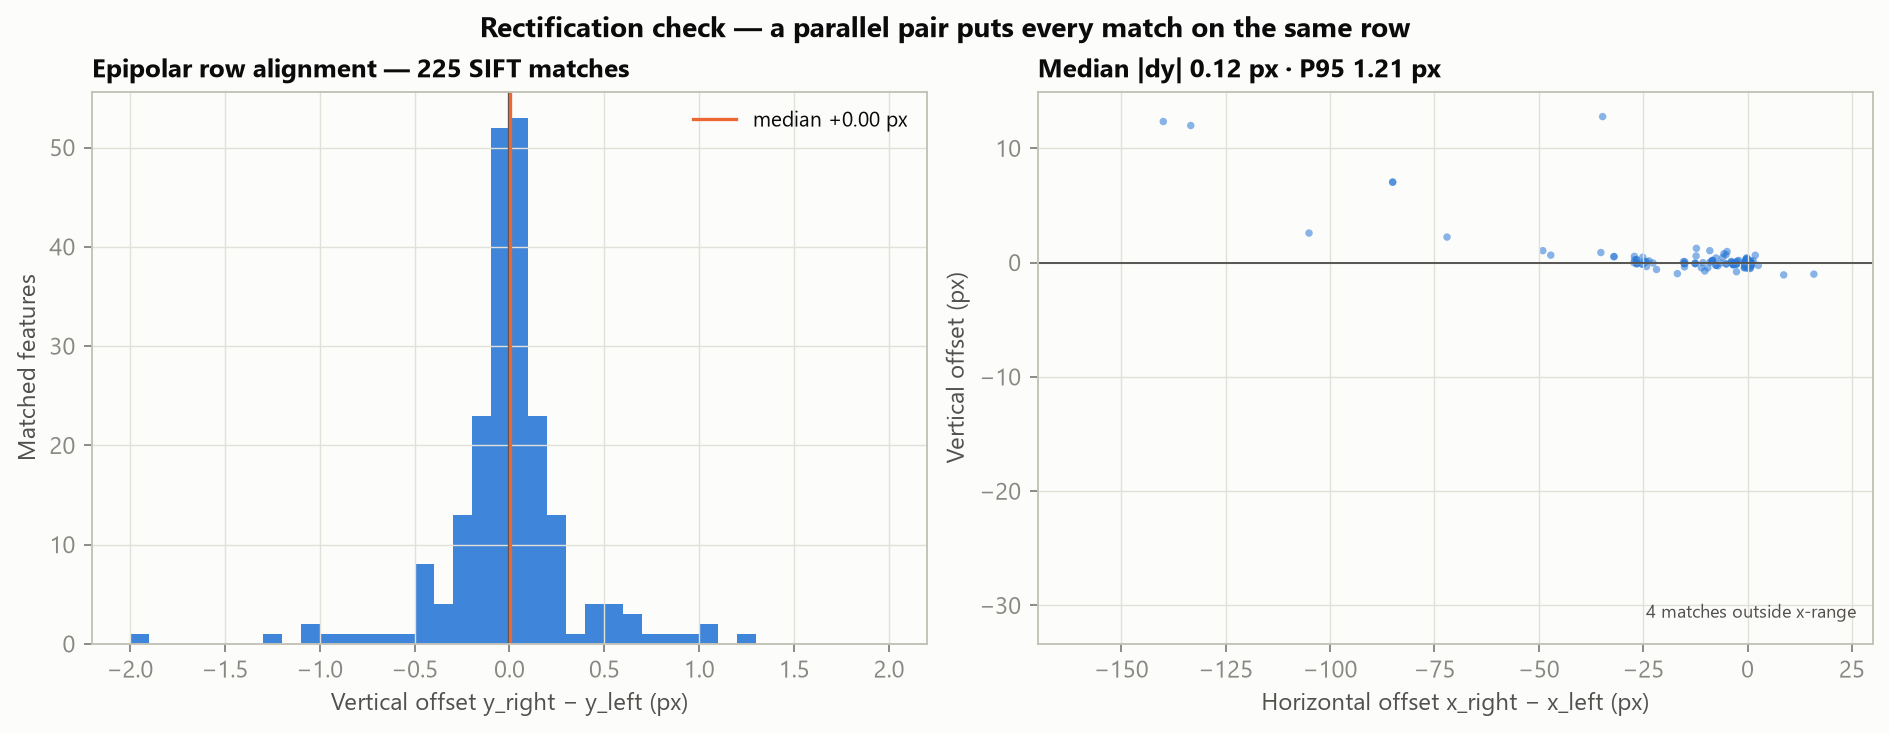

In [6]:
for name in ['fig01_input_pair.png', 'fig02_depth_comparison.png',
             'fig03_scatter.png', 'fig04_error_vs_depth.png',
             'fig05_error_distribution.png', 'fig06_headline_metrics.png',
             'fig07_cone_regions.png', 'fig08_disparity_consistency.png',
             'fig09_epipolar_check.png', 'fig10_pipeline.png']:
    p = ROOT / 'outputs/stereo_validation/figures' / name
    if p.is_file() and name in ('fig02_depth_comparison.png', 'fig04_error_vs_depth.png',
                                'fig08_disparity_consistency.png', 'fig09_epipolar_check.png'):
        display(Markdown(f'**{name}**'))
        display(Image(filename=str(p), width=1000))


## 5. Caveats and reproduction

- **PERFORMANCE**, not NEURAL: TensorRT DLLs were not on the consumer search path.
- **H.264 3000 kbps**, chunk 1200, transport BOTH, extended `StreamingParameters`
  target fields; first `ENCODING_FAILED` tolerated.
- **Metadata mismatch:** 5.2.0 runtime sends 1,216 bytes; 5.5.1 consumer expects
  2,904 and skips camera settings. K and baseline passed.
- **Static frame:** duplicate-frame warnings / IDR requests; one capture.
- **Run-to-run variation:** two captures gave MAE 2.800 and 3.117 m; this
  notebook uses the final capture (3.117 m).
- The stock `04_run_zed_three_way_EXPERIMENTAL.cmd` fails; the fixed producer is
  documented in `ZED_SDK_SIMULATION_RESULT.md` and preserved in `analysis/`.

See `RUN_SUMMARY.md` and `AI_HANDOFF_NOTES.md` for the full command/test matrix
and the do-not-repeat diagnosis notes.
